# Barcelona vs PSG – 3 ML Models Compared
Goal: predict a match result (Home win / Draw / Away win) from **recent form**, then apply the models to tonight's **PSG (home) vs Barcelona (away)**.

Models: **Logistic Regression**, **Random Forest**, **Gradient Boosting**.

Training data: every LaLiga + Ligue 1 match from your 4 league files (not only Barça/PSG games, since 86 matches would be too few).

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, warnings, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, log_loss, confusion_matrix
warnings.filterwarnings("ignore"); plt.style.use("seaborn-v0_8-whitegrid")
P=Path.cwd()
files=["laliga 25,26.csv","laliga 26,27.csv","F1 (1).csv","F1.csv"]
raw=pd.concat([pd.read_csv(P / f,encoding="utf-8-sig",usecols=["Div","Date","HomeTeam","AwayTeam","FTHG","FTAG","HST","AST"]) for f in files],ignore_index=True)
raw["Date"]=pd.to_datetime(raw.Date,dayfirst=True); raw=raw.dropna().sort_values("Date").reset_index(drop=True)
raw["y"]=np.select([raw.FTHG>raw.FTAG,raw.FTHG<raw.FTAG],["H","A"],"D")
print(len(raw),"matches |",raw.Div.value_counts().to_dict()); print(raw.y.value_counts(normalize=True).round(2).to_dict())

818 matches | {'SP1': 458, 'F1': 360}
{'H': 0.47, 'A': 0.28, 'D': 0.25}


## 1. Feature engineering
For each team *before* each match: average points, goals for, goals against and shots on target over its **last 5** games (plus points over last 10). The model uses the **home-minus-away difference** of each (5 features). Only past games are used, so there is no leakage.

In [2]:
# long table: one row per team per match
h=raw.assign(team=raw.HomeTeam,gf=raw.FTHG,ga=raw.FTAG,sot=raw.HST); a=raw.assign(team=raw.AwayTeam,gf=raw.FTAG,ga=raw.FTHG,sot=raw.AST)
L=pd.concat([h.assign(side="h"),a.assign(side="a")]).sort_values(["team","Date"])
L["pts"]=np.select([L.gf>L.ga,L.gf==L.ga],[3,1],0)
g=L.groupby("team")
for c in ["pts","gf","ga","sot"]: L[c+"5"]=g[c].transform(lambda s:s.shift(1).rolling(5,min_periods=3).mean())
L["pts10"]=g.pts.transform(lambda s:s.shift(1).rolling(10,min_periods=3).mean())
feat=["pts5","gf5","ga5","sot5","pts10"]
H=L[L.side=="h"][feat].add_prefix("h_"); A=L[L.side=="a"][feat].add_prefix("a_")
X=raw[["y","Date"]].join(H).join(A)           # aligned on the original match index
for c in feat: X["d_"+c]=X["h_"+c]-X["a_"+c]
X=X.dropna().reset_index(drop=True); cols=["d_"+c for c in feat]   # only home-minus-away differences: simpler, less overfitting
print(len(X),"usable matches,",len(cols),"features"); X[["y"]+cols].head(3).round(2)

746 usable matches, 5 features


,y,d_pts5,d_gf5,d_ga5,d_sot5,d_pts10
0,D,-0.67,0.33,1.00,1.33,-0.67
1,H,0.00,0.00,-1.33,-0.33,0.00
2,H,0.00,1.00,1.00,2.00,0.00


## 2. Train/test split (by time)
First 75% of matches (oldest) train the models, the latest 25% test them – like predicting the future. A 'most common class' baseline is included for reference.

In [3]:
cut=int(len(X)*.75); tr,te=X.iloc[:cut],X.iloc[cut:]
Xtr,ytr,Xte,yte=tr[cols],tr.y,te[cols],te.y
models={"Logistic Regression":make_pipeline(StandardScaler(),LogisticRegression(C=0.3,max_iter=1000)),
        "Random Forest":RandomForestClassifier(n_estimators=300,max_depth=4,min_samples_leaf=8,random_state=0),
        "Gradient Boosting":GradientBoostingClassifier(n_estimators=80,max_depth=2,learning_rate=0.05,subsample=.8,random_state=0)}
CLASS_LABELS=np.array(["A","D","H"])
base=ytr.value_counts(normalize=True)
base_pred=np.repeat(base.idxmax(),len(yte))
base_proba=np.tile(base.reindex(CLASS_LABELS).fillna(0).values,(len(yte),1))
rows=[{"Model":"Baseline (class share)","Accuracy":accuracy_score(yte,base_pred),
       "Macro F1":f1_score(yte,base_pred,labels=CLASS_LABELS,average="macro",zero_division=0),
       "Log loss":log_loss(yte,base_proba,labels=CLASS_LABELS)}]
pred={}; model_proba=[]
for n,m_ in models.items():
    m_.fit(Xtr,ytr); p=m_.predict_proba(Xte); pred[n]=m_.predict(Xte)
    aligned=np.zeros((len(yte),len(CLASS_LABELS)))
    for j,label in enumerate(m_.classes_): aligned[:,CLASS_LABELS==label]=p[:,j:j+1]
    model_proba.append(aligned)
    rows.append({"Model":n,"Accuracy":accuracy_score(yte,pred[n]),
                 "Macro F1":f1_score(yte,pred[n],labels=CLASS_LABELS,average="macro",zero_division=0),
                 "Log loss":log_loss(yte,aligned,labels=CLASS_LABELS)})
ensemble_proba=np.mean(model_proba,axis=0)
pred["Average of 3"]=CLASS_LABELS[np.argmax(ensemble_proba,axis=1)]
rows.append({"Model":"Average of 3","Accuracy":accuracy_score(yte,pred["Average of 3"]),
             "Macro F1":f1_score(yte,pred["Average of 3"],labels=CLASS_LABELS,average="macro",zero_division=0),
             "Log loss":log_loss(yte,ensemble_proba,labels=CLASS_LABELS)})
res=pd.DataFrame(rows).set_index("Model"); print(f"train {len(tr)} | test {len(te)}"); res.round(3)

train 559 | test 187


,Accuracy,Log loss
Model,,
Baseline (class share),0.471,1.056
Logistic Regression,0.497,1.024
Random Forest,0.481,1.031
Gradient Boosting,0.455,1.034


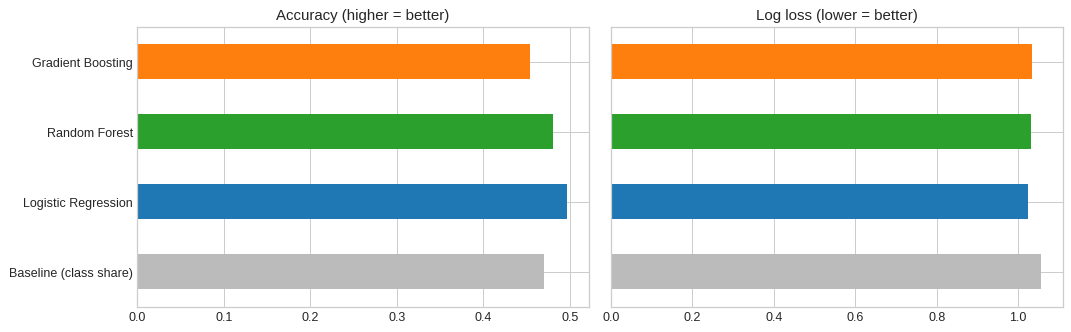

In [4]:
fig,ax=plt.subplots(1,3,figsize=(15,4)); cl=["#bbbbbb","#1f77b4","#2ca02c","#ff7f0e","#9467bd"]
res.Accuracy.plot.barh(ax=ax[0],color=cl,title="Accuracy (higher = better)")
res["Macro F1"].plot.barh(ax=ax[1],color=cl,title="Macro F1 (higher = better)")
res["Log loss"].plot.barh(ax=ax[2],color=cl,title="Log loss (lower = better)")
for a_ in ax: a_.set_ylabel("")
ax[1].set_yticklabels([]); ax[2].set_yticklabels([]); plt.tight_layout(); plt.show()

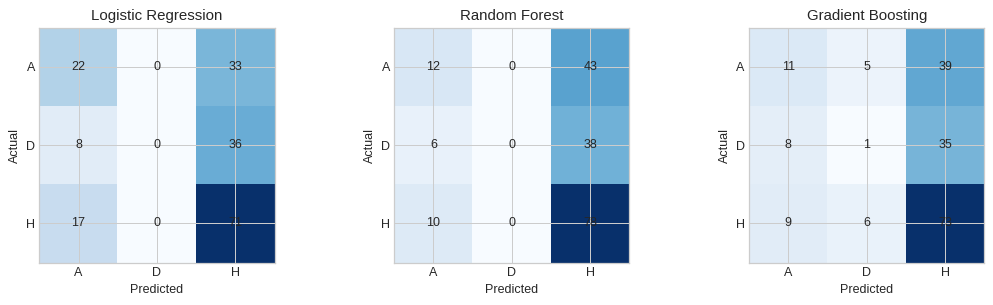

In [5]:
fig,ax=plt.subplots(1,4,figsize=(15,3.5)); lab=["A","D","H"]
for a_,(n,pr) in zip(ax,pred.items()):
    cm=confusion_matrix(yte,pr,labels=lab); a_.imshow(cm,cmap="Blues"); a_.set(title=n,xticks=range(3),yticks=range(3),xticklabels=lab,yticklabels=lab,xlabel="Predicted",ylabel="Actual")
    for i in range(3):
        for j in range(3): a_.text(j,i,cm[i,j],ha="center",va="center")
plt.tight_layout(); plt.show()

## 3. What drives the predictions?

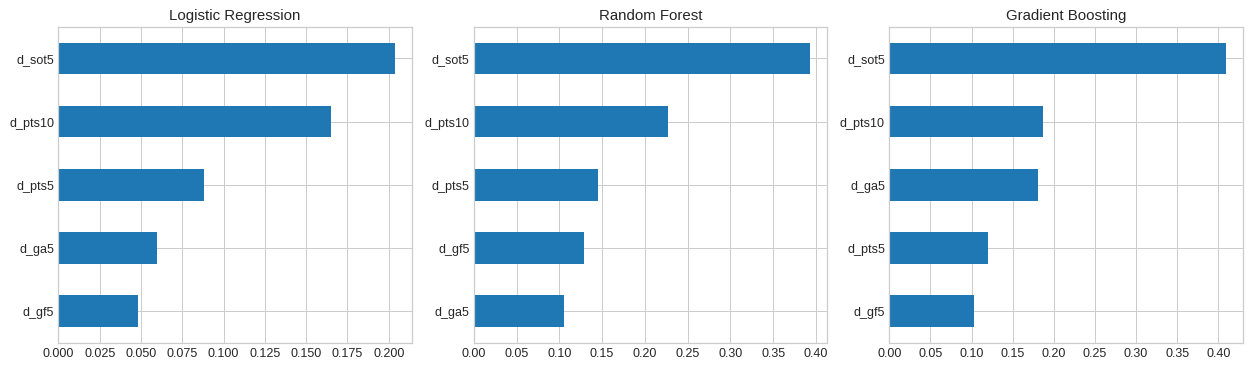

In [6]:
fig,ax=plt.subplots(1,3,figsize=(14,4.2))
lr=models["Logistic Regression"][-1]; co=pd.Series(np.abs(lr.coef_).mean(0),index=cols)
imp=[co,pd.Series(models["Random Forest"].feature_importances_,index=cols),pd.Series(models["Gradient Boosting"].feature_importances_,index=cols)]
for a_,n,s in zip(ax,models,imp): s.sort_values().tail(6).plot.barh(ax=a_,title=n); 
plt.tight_layout(); plt.show()

## 4. Tonight: PSG (home) vs Barcelona (away)
Features = each team's form over its most recent league games (Barça from LaLiga, PSG from Ligue 1). Models are refit on **all** matches first.

In [7]:
def now(team):
    d=L[L.team==team]; return pd.Series({"pts5":d.pts.tail(5).mean(),"gf5":d.gf.tail(5).mean(),"ga5":d.ga.tail(5).mean(),"sot5":d.sot.tail(5).mean(),"pts10":d.pts.tail(10).mean()})
ps,ba=now("Paris SG"),now("Barcelona")
row=pd.DataFrame([{"d_"+k:ps[k]-ba[k] for k in feat}])[cols]
out={}
for n,m_ in models.items():
    m_.fit(X[cols],X.y); p=pd.Series(m_.predict_proba(row)[0],index=m_.classes_); out[n]=[p["H"],p["D"],p["A"]]
T=pd.DataFrame(out,index=["PSG win","Draw","Barça win"]).T*100; T.loc["Average of 3"]=T.mean()
print(pd.DataFrame({"PSG":ps,"Barcelona":ba}).round(2).T.to_string()); T.round(1)

           pts5  gf5  ga5  sot5  pts10
PSG         2.0  1.8  1.2   7.8    1.8
Barcelona   3.0  4.4  1.0   8.0    2.7


,PSG win,Draw,Barça win
Logistic Regression,40.4,30.2,29.4
Random Forest,41.1,30.0,28.9
Gradient Boosting,44.6,31.8,23.6
Average of 3,42.1,30.7,27.3


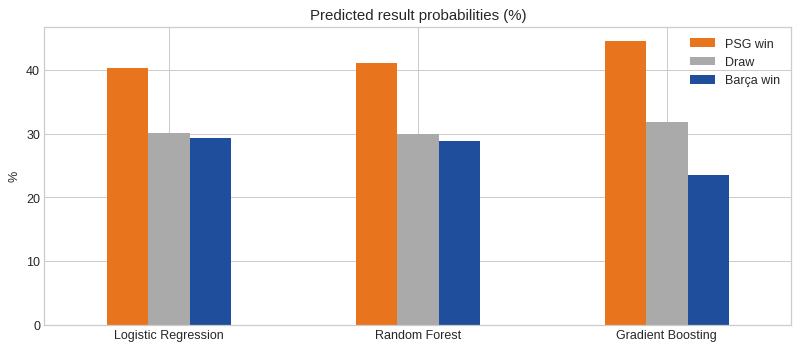

In [8]:
T.iloc[:3].plot.bar(color=["#e8741e","#aaaaaa","#1f4e9c"],rot=0,figsize=(9,4),title="Predicted result probabilities (%)"); plt.ylabel("%"); plt.tight_layout(); plt.show()

In [9]:
comparison=res.drop("Baseline (class share)")
best=comparison["Log loss"].idxmin(); avg=T.loc["Average of 3"]
print("Held-out comparison (same time-ordered test matches):")
print(comparison[["Accuracy","Macro F1","Log loss"]].round(3).to_string())
print(f"Lowest held-out log loss: {best}")
print(f"Ensemble average -> PSG {avg['PSG win']:.0f}% | Draw {avg['Draw']:.0f}% | Barça {avg['Barça win']:.0f}%")

Best on the test set (lowest log loss): Logistic Regression
Ensemble average -> PSG 42% | Draw 31% | Barça 27%


## 5. Takeaways & honest caveats
- Football results are very noisy: the models should beat the baseline only slightly, and **accuracy around 50% is normal** for 3-way predictions.
- Accuracy can hide weak performance on less-common outcomes such as draws, so compare macro F1 (equal weight per class) and log loss (probability quality) alongside accuracy.
- The probability average is an experiment, not a guaranteed improvement. The table above compares it with each individual model on exactly the same held-out matches; judge it by those results rather than assuming it is better.
- Form features are league-relative: Barça's and PSG's recent numbers come from different leagues with different opposition, so the comparison is approximate.
- Models don't know home/away tonight's specifics (injuries, line-ups, Champions League intensity).
- The earlier rivalry notebook combined a Poisson model, head-to-head and bookmaker odds; compare its numbers with the ensemble above.